In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("Desktop/marketing_campaign.csv", sep="\t", encoding="cp1252"
)

df.head()


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [2]:
print(df.shape)
print(df.info())
print(df.isnull().sum())
print(df.describe())

(2240, 29)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 n

In [3]:
df.duplicated().sum()

0

In [4]:

df['Income'].isnull().sum()

24

In [5]:
purchase_columns = [
    'NumWebPurchases',
    'NumCatalogPurchases',
    'NumStorePurchases'
]

df['Total_Purchases'] = df[purchase_columns].sum(axis=1)

In [6]:
spending_columns = [
    'MntWines',
    'MntFruits',
    'MntMeatProducts',
    'MntFishProducts',
    'MntSweetProducts',
    'MntGoldProds'
]

df['Total_Spending'] = df[spending_columns].sum(axis=1)

In [7]:
campaign_columns = [
    'AcceptedCmp1',
    'AcceptedCmp2',
    'AcceptedCmp3',
    'AcceptedCmp4',
    'AcceptedCmp5'
]

df['Total_Campaign_Accepted'] = df[campaign_columns].sum(axis=1)

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

<Axes: xlabel='Total_Spending', ylabel='Count'>

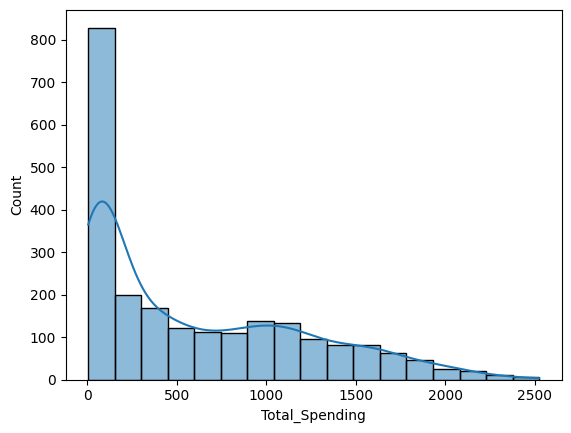

In [9]:
sns.histplot(df['Total_Spending'], kde=True)

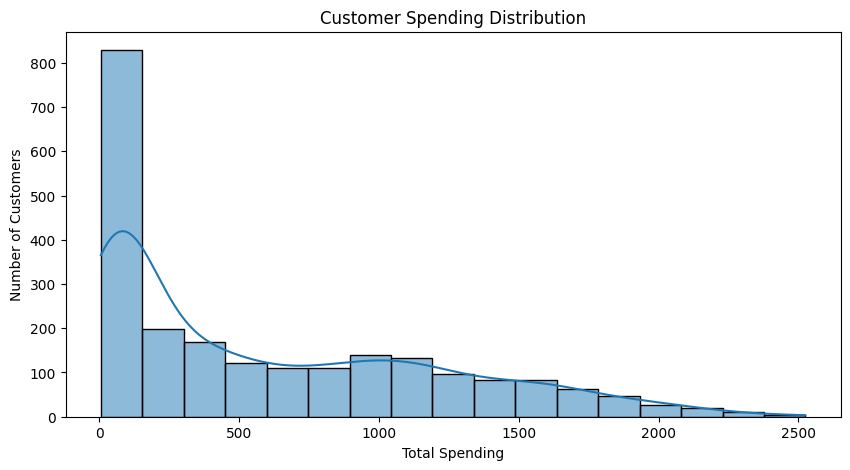

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(df['Total_Spending'], kde=True)

plt.title('Customer Spending Distribution')
plt.xlabel('Total Spending')
plt.ylabel('Number of Customers')
plt.show()

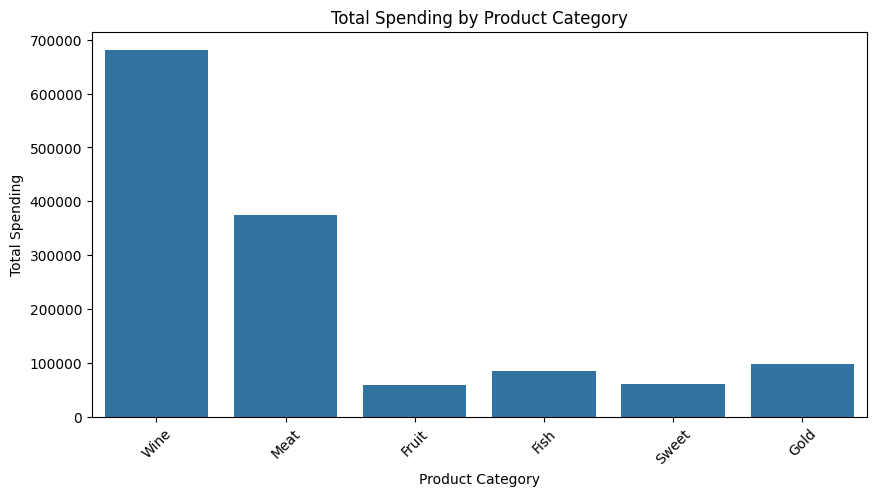

In [11]:
product_spending = {
    'Wine': df['MntWines'].sum(),
    'Meat': df['MntMeatProducts'].sum(),
    'Fruit': df['MntFruits'].sum(),
    'Fish': df['MntFishProducts'].sum(),
    'Sweet': df['MntSweetProducts'].sum(),
    'Gold': df['MntGoldProds'].sum()
}

product_spending_df = pd.DataFrame(
    list(product_spending.items()),
    columns=['Product_Category', 'Total_Spending']
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=product_spending_df,
    x='Product_Category',
    y='Total_Spending'
)

plt.title('Total Spending by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Spending')
plt.xticks(rotation=45)
plt.show()

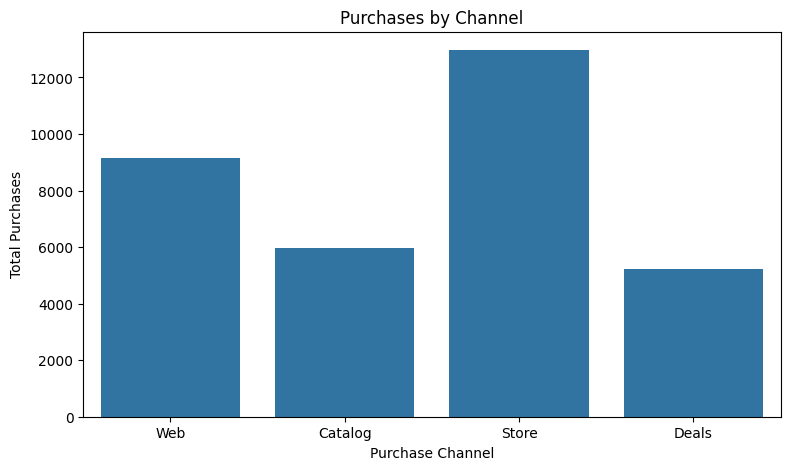

In [12]:
channel_purchases = {
    'Web': df['NumWebPurchases'].sum(),
    'Catalog': df['NumCatalogPurchases'].sum(),
    'Store': df['NumStorePurchases'].sum(),
    'Deals': df['NumDealsPurchases'].sum()
}

channel_df = pd.DataFrame(
    list(channel_purchases.items()),
    columns=['Channel', 'Total_Purchases']
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=channel_df,
    x='Channel',
    y='Total_Purchases'
)

plt.title('Purchases by Channel')
plt.xlabel('Purchase Channel')
plt.ylabel('Total Purchases')
plt.show()

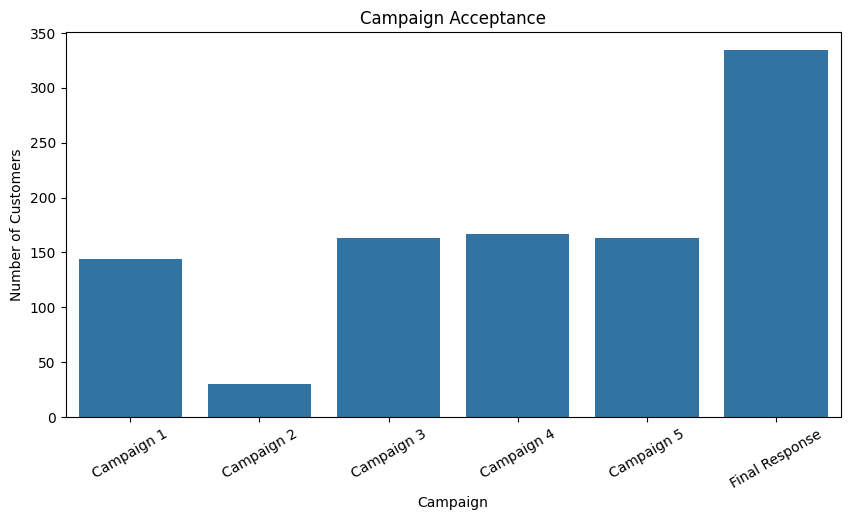

In [13]:
campaign_acceptance = {
    'Campaign 1': df['AcceptedCmp1'].sum(),
    'Campaign 2': df['AcceptedCmp2'].sum(),
    'Campaign 3': df['AcceptedCmp3'].sum(),
    'Campaign 4': df['AcceptedCmp4'].sum(),
    'Campaign 5': df['AcceptedCmp5'].sum(),
    'Final Response': df['Response'].sum()
}

campaign_df = pd.DataFrame(
    list(campaign_acceptance.items()),
    columns=['Campaign', 'Accepted_Customers']
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=campaign_df,
    x='Campaign',
    y='Accepted_Customers'
)

plt.title('Campaign Acceptance')
plt.xlabel('Campaign')
plt.ylabel('Number of Customers')
plt.xticks(rotation=30)
plt.show()

In [14]:
features = [
    'Recency',
    'Total_Purchases',
    'Total_Spending',
    'NumWebPurchases',
    'NumCatalogPurchases',
    'NumStorePurchases',
    'NumDealsPurchases'
]

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X = scaler.fit_transform(df[features])

In [16]:
from sklearn.cluster import KMeans

inertia = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X)
    inertia.append(model.inertia_)

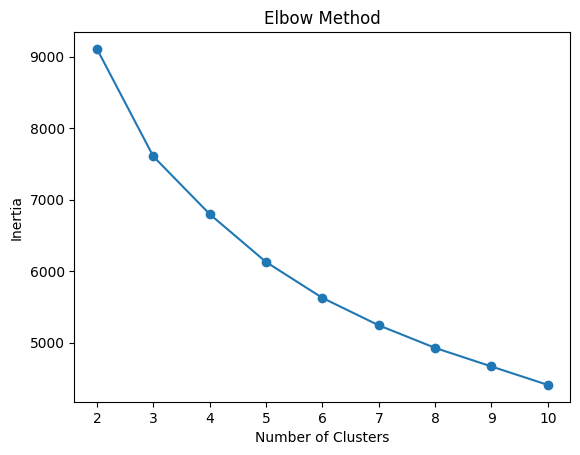

In [17]:
plt.plot(range(2, 11), inertia, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

In [25]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X)

In [26]:
segment_summary = df.groupby('Cluster').agg({
    'Income': 'mean',
    'Recency': 'mean',
    'Total_Spending': 'mean',
    'Total_Purchases': 'mean',
    'Total_Campaign_Accepted': 'mean',
    'Response': 'mean'
}).round(2)

segment_summary

,Income,Recency,Total_Spending,Total_Purchases,Total_Campaign_Accepted,Response
Cluster,,,,,,
0,37295.81,77.43,135.80,6.38,0.08,0.04
1,72726.75,49.74,1271.04,19.79,0.62,0.23
2,53787.83,46.15,631.01,15.99,0.22,0.17
3,36624.00,25.90,108.70,5.95,0.10,0.12


In [27]:
campaign_rates = df[campaign_columns].mean() * 100

campaign_rates

AcceptedCmp1    6.428571
AcceptedCmp2    1.339286
AcceptedCmp3    7.276786
AcceptedCmp4    7.455357
AcceptedCmp5    7.276786
dtype: float64

In [28]:
segment_value = df.groupby('Cluster').agg(
    Customers=('ID', 'count'),
    Avg_Spending=('Total_Spending', 'mean'),
    Total_Spending=('Total_Spending', 'sum'),
    Avg_Purchases=('Total_Purchases', 'mean'),
    Avg_Recency=('Recency', 'mean'),
    Response_Rate=('Response', 'mean')
)

In [29]:
segment_value['Response_Rate'] *= 100

In [30]:
# Create Age column
df['Age'] = 2014 - df['Year_Birth']

# Check that it was created
df[['Year_Birth', 'Age']].head()

,Year_Birth,Age
0,1957,57
1,1954,60
2,1965,49
3,1984,30
4,1981,33


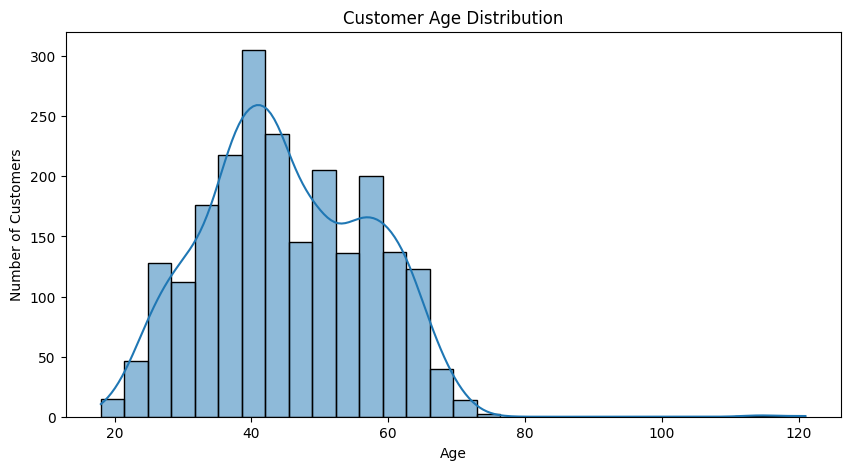

In [32]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['Age'],
    bins=30,
    kde=True
)

plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()

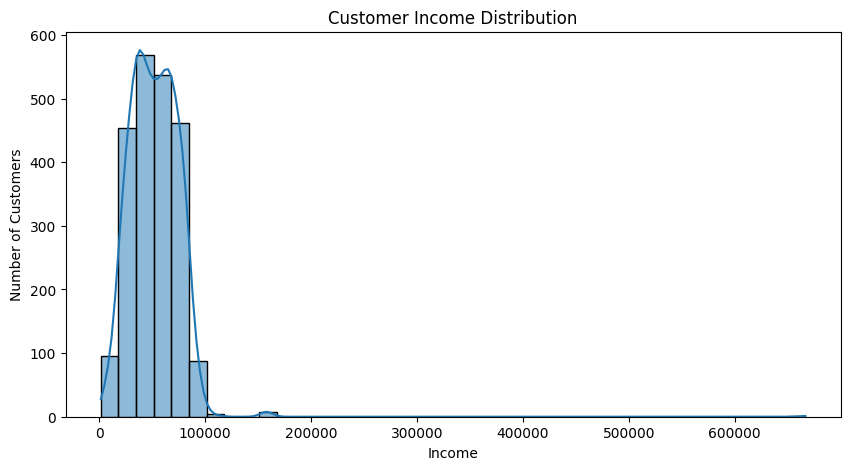

In [34]:
#Income 
plt.figure(figsize=(10, 5))

sns.histplot(
    df['Income'],
    bins=40,
    kde=True
)

plt.title('Customer Income Distribution')
plt.xlabel('Income')
plt.ylabel('Number of Customers')

plt.show()

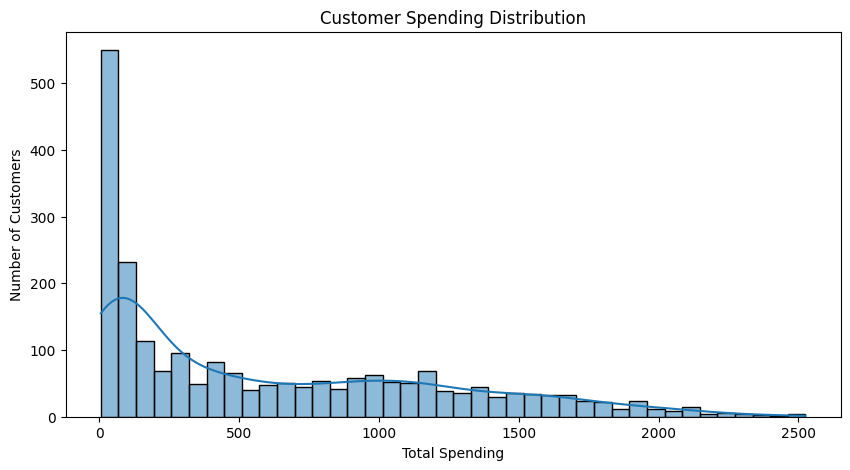

In [36]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['Total_Spending'],
    bins=40,
    kde=True
)

plt.title('Customer Spending Distribution')
plt.xlabel('Total Spending')
plt.ylabel('Number of Customers')

plt.show()

In [39]:
product_spending = df[spending_columns].sum().sort_values(
    ascending=False
)

product_spending

MntWines            680816
MntMeatProducts     373968
MntGoldProds         98609
MntFishProducts      84057
MntSweetProducts     60621
MntFruits            58917
dtype: int64

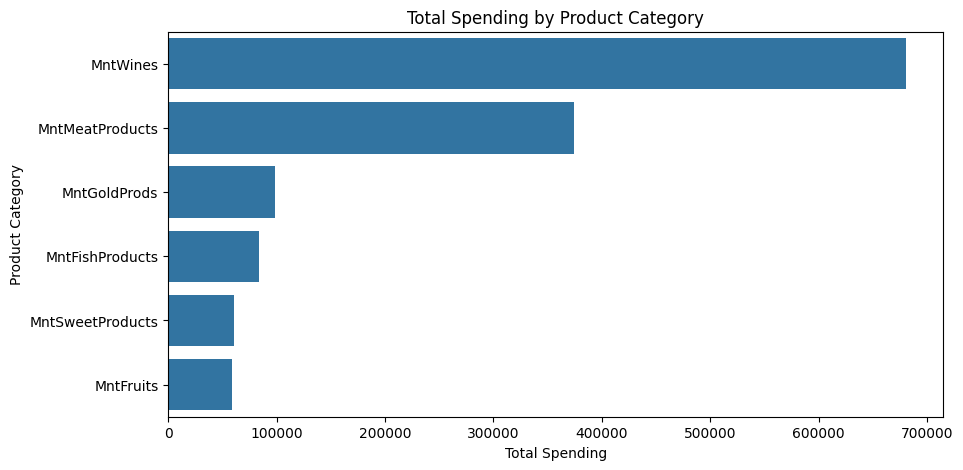

In [40]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=product_spending.values,
    y=product_spending.index
)

plt.title('Total Spending by Product Category')
plt.xlabel('Total Spending')
plt.ylabel('Product Category')

plt.show()

In [43]:
channel_columns = [
    'NumWebPurchases',
    'NumCatalogPurchases',
    'NumStorePurchases'
]

channel_totals = df[channel_columns].sum().sort_values(
    ascending=False
)

channel_totals

NumStorePurchases      12970
NumWebPurchases         9150
NumCatalogPurchases     5963
dtype: int64

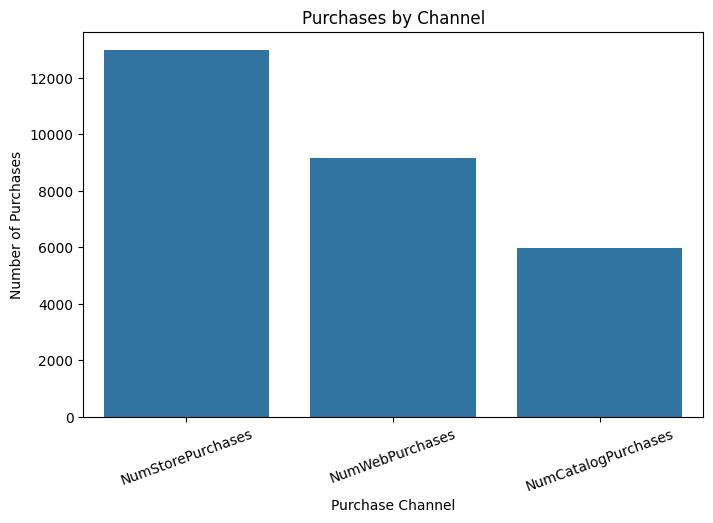

In [45]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=channel_totals.index,
    y=channel_totals.values
)

plt.title('Purchases by Channel')
plt.xlabel('Purchase Channel')
plt.ylabel('Number of Purchases')

plt.xticks(rotation=20)

plt.show()

In [46]:
response_rate = df['Response'].mean() * 100

print(f"Overall Response Rate: {response_rate:.2f}%")

Overall Response Rate: 14.91%


In [47]:
# Create spending groups based on total customer spending
df['Spending_Group'] = pd.qcut(
    df['Total_Spending'],
    q=4,
    labels=['Low', 'Medium', 'High', 'Very High']
)

# Check the result
df[['Total_Spending', 'Spending_Group']].head()

,Total_Spending,Spending_Group
0,1617,Very High
1,27,Low
2,776,High
3,53,Low
4,422,High


In [49]:
response_by_spending = (
    df.groupby('Spending_Group', observed=True)['Response']
    .mean()
    .mul(100)
)

response_by_spending

Spending_Group
Low           5.535714
Medium       12.299465
High         11.806798
Very High    30.000000
Name: Response, dtype: float64

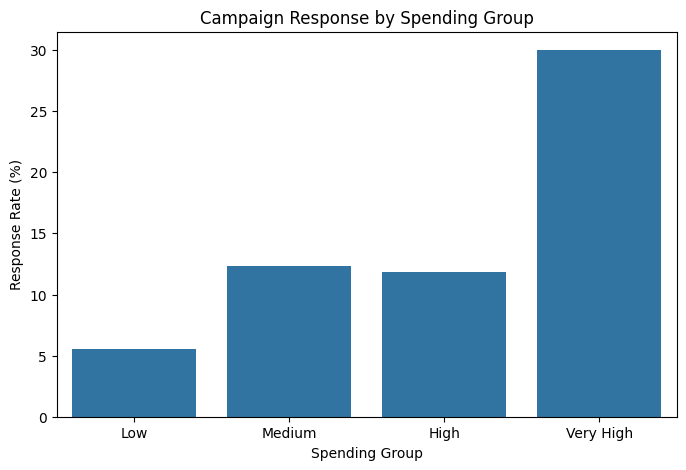

In [51]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=response_by_spending.index,
    y=response_by_spending.values
)

plt.title('Campaign Response by Spending Group')
plt.xlabel('Spending Group')
plt.ylabel('Response Rate (%)')

plt.show()

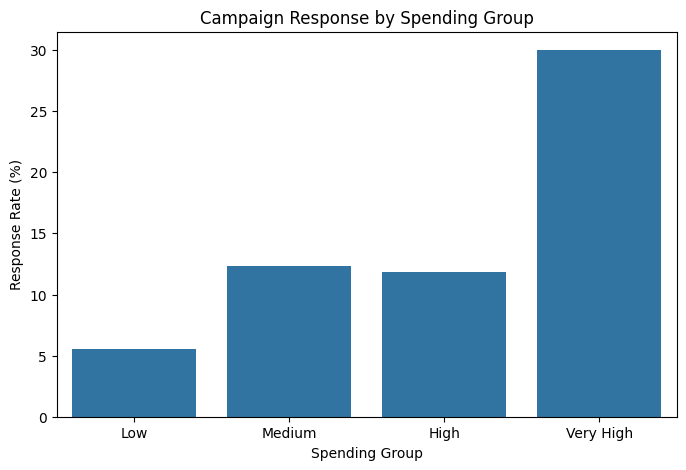

In [58]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=response_by_spending.index,
    y=response_by_spending.values
)

plt.title('Campaign Response by Spending Group')
plt.xlabel('Spending Group')
plt.ylabel('Response Rate (%)')

plt.show()

In [63]:
clustering_features = [
    'Recency',
    'Total_Spending',
    'Total_Purchases',
    'NumDealsPurchases',
    'NumWebPurchases',
    'NumCatalogPurchases',
    'NumStorePurchases'
]

In [66]:
df[clustering_features].describe()

,Recency,Total_Spending,Total_Purchases,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases
count,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000
mean,49.109375,605.798214,12.537054,2.325000,4.084821,2.662054,5.790179
std,28.962453,602.249288,7.205741,1.932238,2.778714,2.923101,3.250958
min,0.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,24.000000,68.750000,6.000000,1.000000,2.000000,0.000000,3.000000
50%,49.000000,396.000000,12.000000,2.000000,4.000000,2.000000,5.000000
75%,74.000000,1045.500000,18.000000,3.000000,6.000000,4.000000,8.000000
max,99.000000,2525.000000,32.000000,15.000000,27.000000,28.000000,13.000000


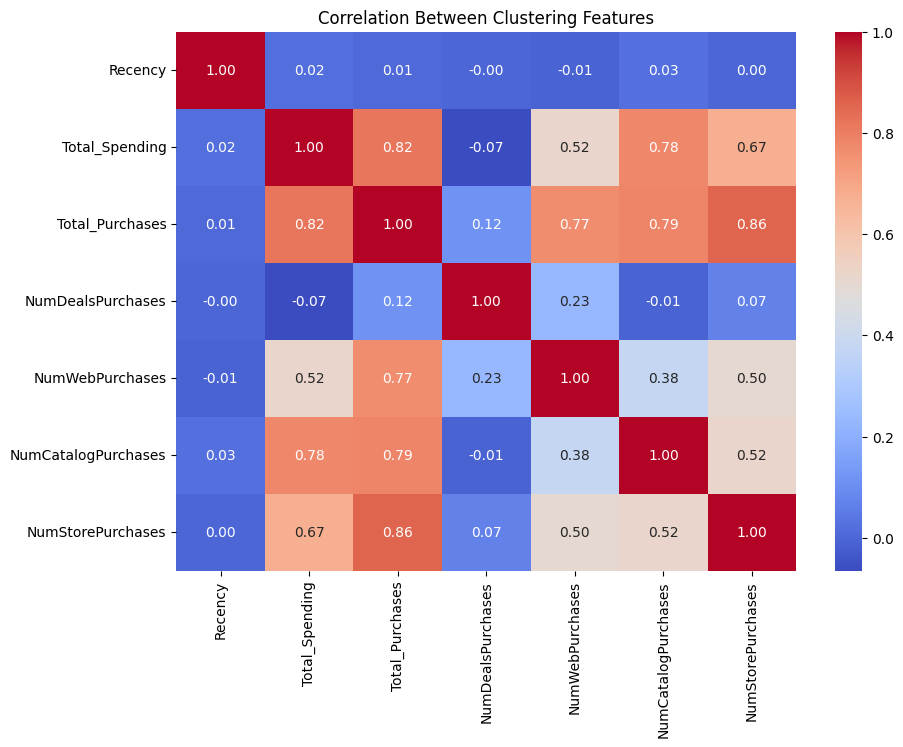

In [70]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df[clustering_features].corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title('Correlation Between Clustering Features')

plt.show()

In [73]:
scaler = StandardScaler()

X = scaler.fit_transform(
    df[clustering_features]
)

In [74]:
inertia = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X)

    inertia.append(kmeans.inertia_)

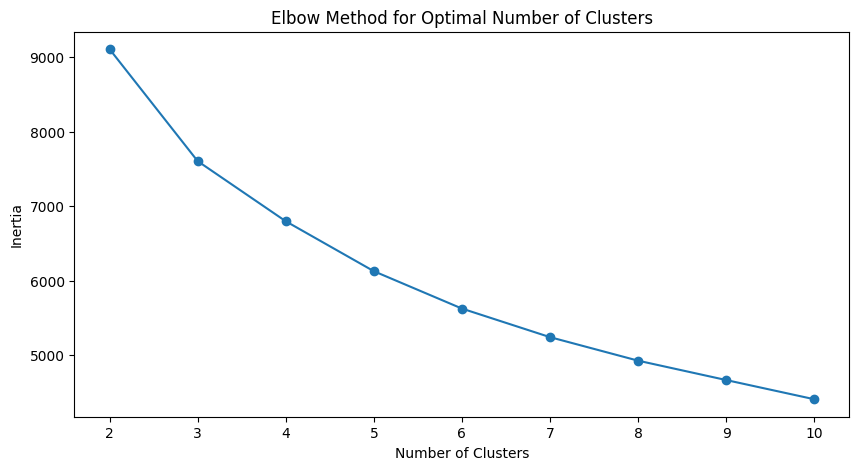

In [77]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(2, 11),
    inertia,
    marker='o'
)

plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')

plt.show()

In [79]:
from sklearn.metrics import silhouette_score

In [80]:
silhouette_scores = {}

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X)

    score = silhouette_score(
        X,
        labels
    )

    silhouette_scores[k] = score

    print(
        f"K = {k}, "
        f"Silhouette Score = {score:.3f}"
    )

K = 2, Silhouette Score = 0.389
K = 3, Silhouette Score = 0.342
K = 4, Silhouette Score = 0.270
K = 5, Silhouette Score = 0.245
K = 6, Silhouette Score = 0.244
K = 7, Silhouette Score = 0.247
K = 8, Silhouette Score = 0.246


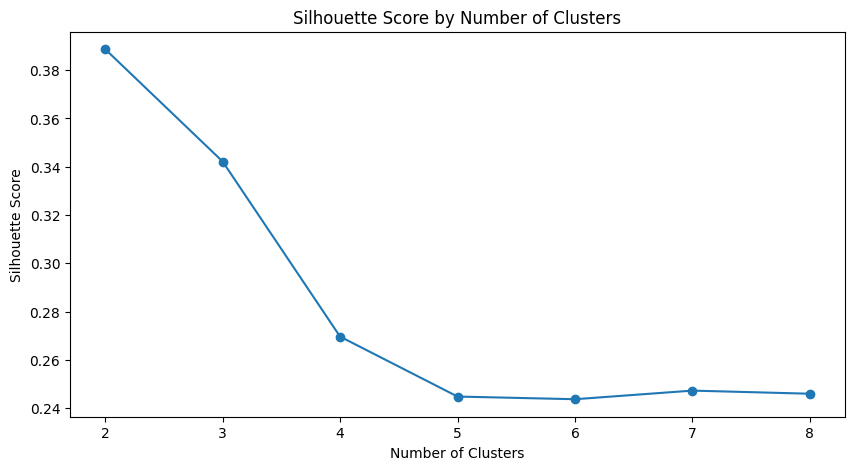

In [81]:
plt.figure(figsize=(10, 5))

plt.plot(
    list(silhouette_scores.keys()),
    list(silhouette_scores.values()),
    marker='o'
)

plt.title('Silhouette Score by Number of Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')

plt.show()

In [82]:
optimal_k = 4

In [83]:
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X)

In [86]:
df['Cluster'].value_counts().sort_index()

Cluster
0    501
1    776
2    379
3    584
Name: count, dtype: int64

In [87]:
cluster_summary = df.groupby('Cluster').agg(
    Customers=('ID', 'count'),
    Avg_Age=('Age', 'mean'),
    Avg_Income=('Income', 'mean'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Spending=('Total_Spending', 'mean'),
    Total_Spending=('Total_Spending', 'sum'),
    Avg_Purchases=('Total_Purchases', 'mean'),
    Avg_Web_Purchases=('NumWebPurchases', 'mean'),
    Avg_Catalog_Purchases=('NumCatalogPurchases', 'mean'),
    Avg_Store_Purchases=('NumStorePurchases', 'mean'),
    Avg_Campaign_Acceptance=('Total_Campaign_Accepted', 'mean'),
    Response_Rate=('Response', 'mean')
)

cluster_summary

,Customers,Avg_Age,Avg_Income,Avg_Recency,Avg_Spending,Total_Spending,Avg_Purchases,Avg_Web_Purchases,Avg_Catalog_Purchases,Avg_Store_Purchases,Avg_Campaign_Acceptance,Response_Rate
Cluster,,,,,,,,,,,,
0,501,43.964072,37295.810976,77.425150,135.796407,68034,6.375250,2.249501,0.716567,3.409182,0.083832,0.035928
1,776,46.652062,72726.746114,49.735825,1271.036082,986324,19.786082,5.524485,5.514175,8.747423,0.623711,0.231959
2,379,47.997361,53787.831551,46.153034,631.007916,239152,15.986807,6.641161,2.614776,6.730871,0.216359,0.171504
3,584,42.493151,36624.001730,25.904110,108.695205,63478,5.952055,2.087329,0.571918,3.292808,0.101027,0.121575


In [88]:
cluster_summary['Response_Rate'] = (
    cluster_summary['Response_Rate'] * 100
)

In [89]:
cluster_summary.round(2)

,Customers,Avg_Age,Avg_Income,Avg_Recency,Avg_Spending,Total_Spending,Avg_Purchases,Avg_Web_Purchases,Avg_Catalog_Purchases,Avg_Store_Purchases,Avg_Campaign_Acceptance,Response_Rate
Cluster,,,,,,,,,,,,
0,501,43.96,37295.81,77.43,135.80,68034,6.38,2.25,0.72,3.41,0.08,3.59
1,776,46.65,72726.75,49.74,1271.04,986324,19.79,5.52,5.51,8.75,0.62,23.20
2,379,48.00,53787.83,46.15,631.01,239152,15.99,6.64,2.61,6.73,0.22,17.15
3,584,42.49,36624.00,25.90,108.70,63478,5.95,2.09,0.57,3.29,0.10,12.16


In [90]:
segment_size = (
    df['Cluster']
    .value_counts()
    .sort_index()
)

segment_size

Cluster
0    501
1    776
2    379
3    584
Name: count, dtype: int64

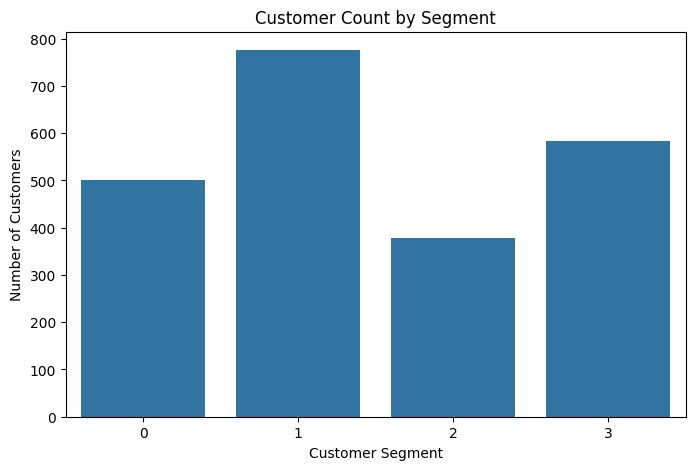

In [91]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=segment_size.index,
    y=segment_size.values
)

plt.title('Customer Count by Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')

plt.show()

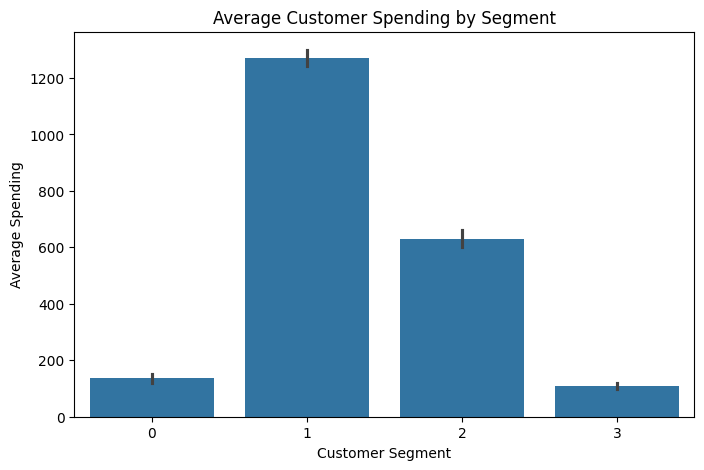

In [92]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='Cluster',
    y='Total_Spending',
    estimator='mean'
)

plt.title('Average Customer Spending by Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Average Spending')

plt.show()

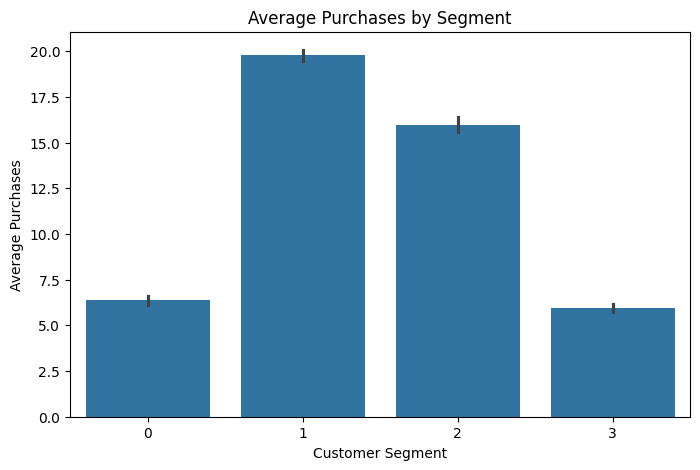

In [94]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='Cluster',
    y='Total_Purchases',
    estimator='mean'
)

plt.title('Average Purchases by Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Average Purchases')

plt.show()

In [97]:
response_by_cluster = (
    df.groupby('Cluster')['Response']
    .mean()
    .mul(100)
)

response_by_cluster

Cluster
0     3.592814
1    23.195876
2    17.150396
3    12.157534
Name: Response, dtype: float64

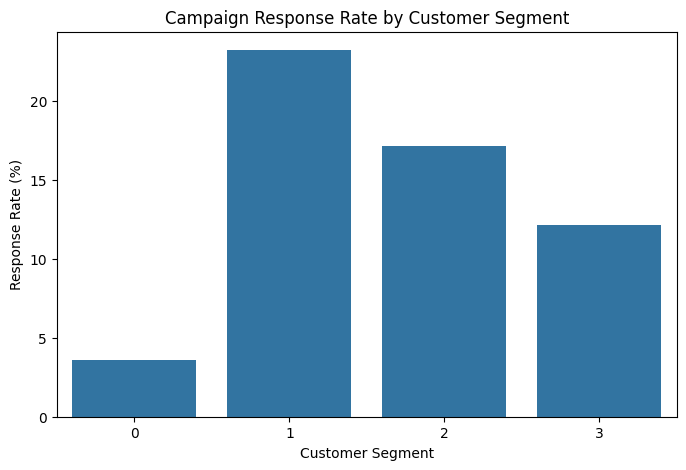

In [98]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=response_by_cluster.index,
    y=response_by_cluster.values
)

plt.title('Campaign Response Rate by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Response Rate (%)')

plt.show()

In [99]:
campaign_segment = (
    df.groupby('Cluster')[campaign_columns]
    .mean()
    .mul(100)
)

campaign_segment.round(2)

,AcceptedCmp1,AcceptedCmp2,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5
Cluster,,,,,
0,0.40,0.20,4.99,2.40,0.40
1,16.62,3.22,8.12,13.92,20.49
2,3.17,0.53,6.86,10.55,0.53
3,0.17,0.34,8.39,1.20,0.00


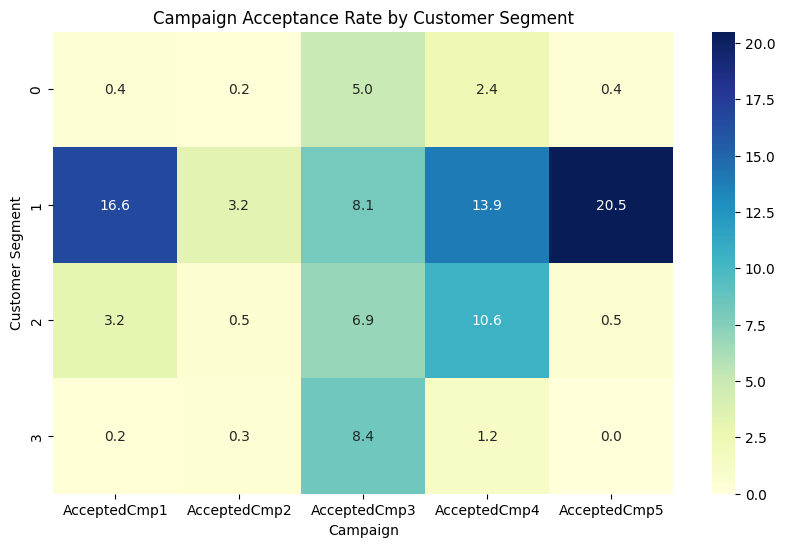

In [100]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    campaign_segment,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu'
)

plt.title('Campaign Acceptance Rate by Customer Segment')
plt.xlabel('Campaign')
plt.ylabel('Customer Segment')

plt.show()

In [101]:
segment_profile = df.groupby('Cluster').agg(
    Customers=('ID', 'count'),
    Avg_Income=('Income', 'mean'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Spending=('Total_Spending', 'mean'),
    Avg_Purchases=('Total_Purchases', 'mean'),
    Avg_Web_Visits=('NumWebVisitsMonth', 'mean'),
    Avg_Campaign_Accepted=('Total_Campaign_Accepted', 'mean'),
    Response_Rate=('Response', 'mean')
).round(2)

segment_profile['Response_Rate'] = (
    segment_profile['Response_Rate'] * 100
)

segment_profile

,Customers,Avg_Income,Avg_Recency,Avg_Spending,Avg_Purchases,Avg_Web_Visits,Avg_Campaign_Accepted,Response_Rate
Cluster,,,,,,,,
0,501,37295.81,77.43,135.80,6.38,6.14,0.08,4.0
1,776,72726.75,49.74,1271.04,19.79,3.47,0.62,23.0
2,379,53787.83,46.15,631.01,15.99,6.50,0.22,17.0
3,584,36624.00,25.90,108.70,5.95,6.29,0.10,12.0


In [102]:
high_value_threshold = df['Total_Spending'].quantile(0.75)

df['High_Value_Customer'] = (
    df['Total_Spending'] >= high_value_threshold
).astype(int)

In [104]:
df['High_Value_Customer'].value_counts()

High_Value_Customer
0    1680
1     560
Name: count, dtype: int64

In [105]:
high_value_by_cluster = (
    df.groupby('Cluster')['High_Value_Customer']
    .mean()
    .mul(100)
)

high_value_by_cluster

Cluster
0     0.598802
1    65.592784
2    12.401055
3     0.171233
Name: High_Value_Customer, dtype: float64

In [106]:
channel_by_cluster = df.groupby('Cluster')[
    [
        'NumWebPurchases',
        'NumCatalogPurchases',
        'NumStorePurchases'
    ]
].mean()

channel_by_cluster.round(2)

,NumWebPurchases,NumCatalogPurchases,NumStorePurchases
Cluster,,,
0,2.25,0.72,3.41
1,5.52,5.51,8.75
2,6.64,2.61,6.73
3,2.09,0.57,3.29


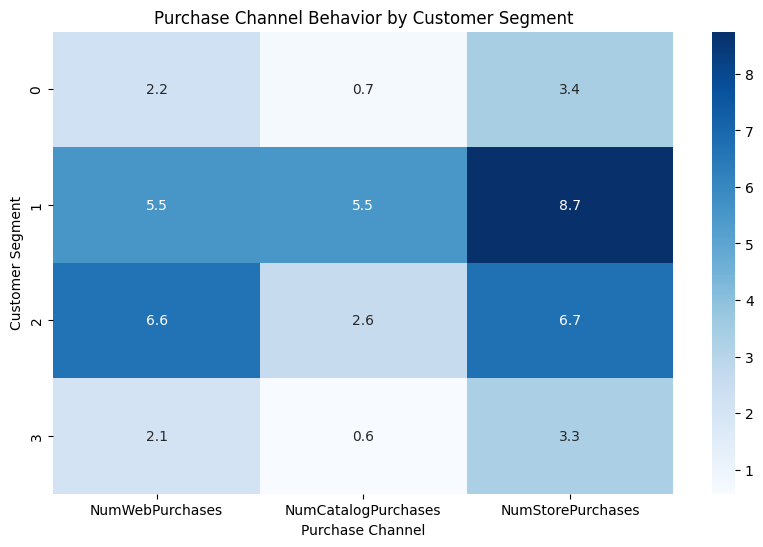

In [110]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    channel_by_cluster,
    annot=True,
    fmt='.1f',
    cmap='Blues'
)

plt.title('Purchase Channel Behavior by Customer Segment')

plt.xlabel('Purchase Channel')
plt.ylabel('Customer Segment')

plt.show()

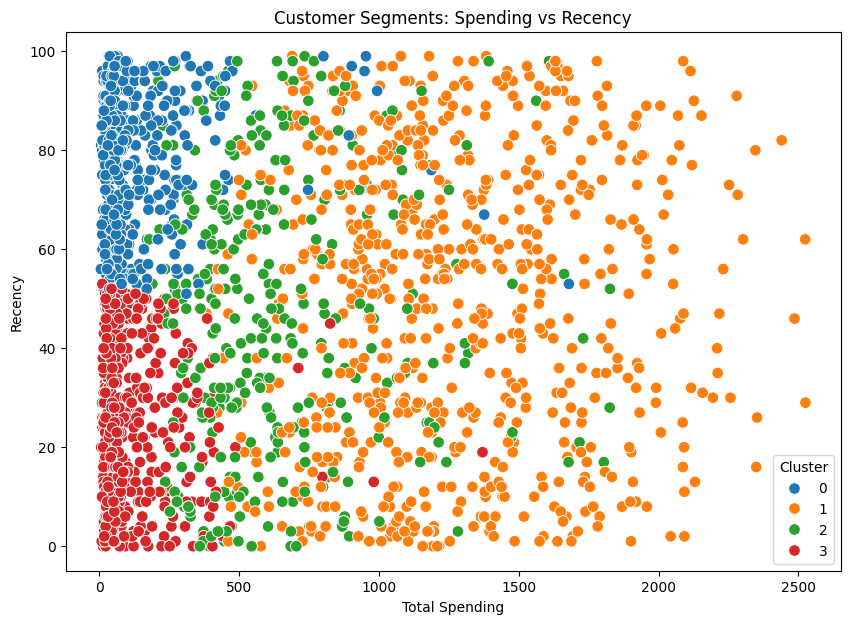

In [114]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x='Total_Spending',
    y='Recency',
    hue='Cluster',
    palette='tab10',
    s=70
)

plt.title('Customer Segments: Spending vs Recency')
plt.xlabel('Total Spending')
plt.ylabel('Recency')

plt.show()

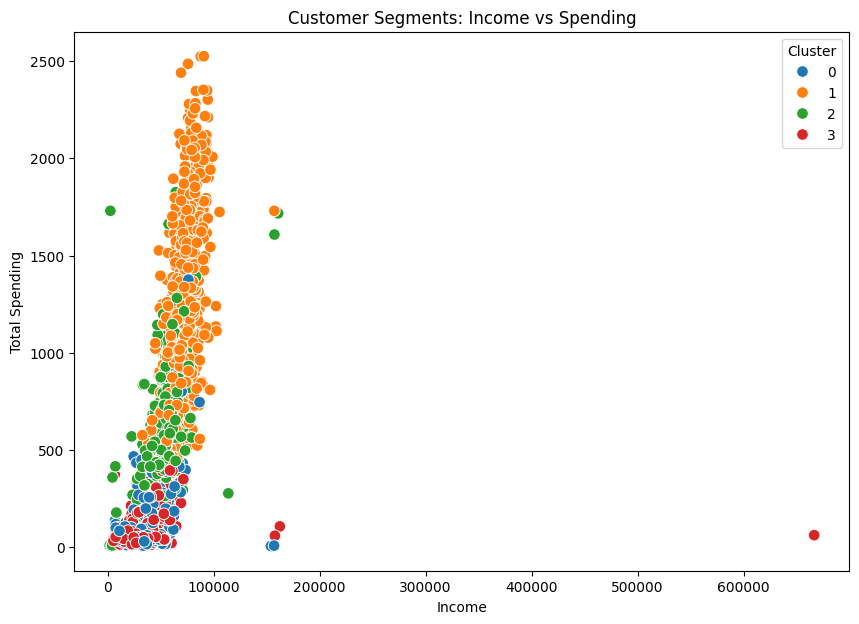

In [117]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x='Income',
    y='Total_Spending',
    hue='Cluster',
    palette='tab10',
    s=70
)

plt.title('Customer Segments: Income vs Spending')
plt.xlabel('Income')
plt.ylabel('Total Spending')

plt.show()

In [118]:
campaign_performance = pd.DataFrame({
    'Campaign': [
        'Campaign 1',
        'Campaign 2',
        'Campaign 3',
        'Campaign 4',
        'Campaign 5',
        'Latest Campaign'
    ],
    'Acceptance_Rate_%': [
        df['AcceptedCmp1'].mean() * 100,
        df['AcceptedCmp2'].mean() * 100,
        df['AcceptedCmp3'].mean() * 100,
        df['AcceptedCmp4'].mean() * 100,
        df['AcceptedCmp5'].mean() * 100,
        df['Response'].mean() * 100
    ]
})

campaign_performance.round(2)

,Campaign,Acceptance_Rate_%
0,Campaign 1,6.43
1,Campaign 2,1.34
2,Campaign 3,7.28
3,Campaign 4,7.46
4,Campaign 5,7.28
5,Latest Campaign,14.91


In [120]:
campaign_responder_count = {
    'Campaign 1': df['AcceptedCmp1'].sum(),
    'Campaign 2': df['AcceptedCmp2'].sum(),
    'Campaign 3': df['AcceptedCmp3'].sum(),
    'Campaign 4': df['AcceptedCmp4'].sum(),
    'Campaign 5': df['AcceptedCmp5'].sum(),
    'Latest Campaign': df['Response'].sum()
}

campaign_responder_count

{'Campaign 1': 144,
 'Campaign 2': 30,
 'Campaign 3': 163,
 'Campaign 4': 167,
 'Campaign 5': 163,
 'Latest Campaign': 334}

In [121]:
marketing_effectiveness = df.groupby('Cluster').agg(
    Customers=('ID', 'count'),
    Avg_Spending=('Total_Spending', 'mean'),
    Avg_Purchases=('Total_Purchases', 'mean'),
    Campaign_Acceptance=('Total_Campaign_Accepted', 'mean'),
    Response_Rate=('Response', 'mean'),
    High_Value_Rate=('High_Value_Customer', 'mean')
)

marketing_effectiveness['Response_Rate'] *= 100
marketing_effectiveness['High_Value_Rate'] *= 100

marketing_effectiveness.round(2)

,Customers,Avg_Spending,Avg_Purchases,Campaign_Acceptance,Response_Rate,High_Value_Rate
Cluster,,,,,,
0,501,135.80,6.38,0.08,3.59,0.60
1,776,1271.04,19.79,0.62,23.20,65.59
2,379,631.01,15.99,0.22,17.15,12.40
3,584,108.70,5.95,0.10,12.16,0.17


In [122]:
cluster_means = df.groupby('Cluster').agg({
    'Total_Spending': 'mean',
    'Recency': 'mean',
    'Response': 'mean',
    'Total_Purchases': 'mean'
})

In [124]:
cluster_means.round(2)

,Total_Spending,Recency,Response,Total_Purchases
Cluster,,,,
0,135.80,77.43,0.04,6.38
1,1271.04,49.74,0.23,19.79
2,631.01,46.15,0.17,15.99
3,108.70,25.90,0.12,5.95


In [125]:
segment_labels = {
    0: 'High-Value Engaged',
    1: 'Low-Engagement',
    2: 'Growth Opportunity',
    3: 'At-Risk Valuable'
}

In [126]:
df['Segment'] = df['Cluster'].map(segment_labels)

In [127]:
df[['ID', 'Cluster', 'Segment']].head(20)

,ID,Cluster,Segment
0,5524,1,Low-Engagement
1,2174,3,At-Risk Valuable
2,4141,1,Low-Engagement
3,6182,3,At-Risk Valuable
4,5324,2,Growth Opportunity
5,7446,1,Low-Engagement
6,965,2,Growth Opportunity
7,6177,3,At-Risk Valuable
8,4855,3,At-Risk Valuable
9,5899,0,High-Value Engaged


In [128]:
final_segment_report = df.groupby('Segment').agg(
    Customers=('ID', 'count'),
    Avg_Income=('Income', 'mean'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Spending=('Total_Spending', 'mean'),
    Avg_Purchases=('Total_Purchases', 'mean'),
    Avg_Web_Purchases=('NumWebPurchases', 'mean'),
    Avg_Store_Purchases=('NumStorePurchases', 'mean'),
    Avg_Campaign_Accepted=('Total_Campaign_Accepted', 'mean'),
    Response_Rate=('Response', 'mean')
).round(2)

final_segment_report['Response_Rate'] *= 100

final_segment_report

,Customers,Avg_Income,Avg_Recency,Avg_Spending,Avg_Purchases,Avg_Web_Purchases,Avg_Store_Purchases,Avg_Campaign_Accepted,Response_Rate
Segment,,,,,,,,,
At-Risk Valuable,584,36624.00,25.90,108.70,5.95,2.09,3.29,0.10,12.0
Growth Opportunity,379,53787.83,46.15,631.01,15.99,6.64,6.73,0.22,17.0
High-Value Engaged,501,37295.81,77.43,135.80,6.38,2.25,3.41,0.08,4.0
Low-Engagement,776,72726.75,49.74,1271.04,19.79,5.52,8.75,0.62,23.0


In [131]:
strategy = pd.DataFrame({
    'Segment': final_segment_report.index,
    'Primary_Metric': final_segment_report['Avg_Spending'].values,
    'Response_Rate_%': final_segment_report['Response_Rate'].values
})

strategy

,Segment,Primary_Metric,Response_Rate_%
0,At-Risk Valuable,108.70,12.0
1,Growth Opportunity,631.01,17.0
2,High-Value Engaged,135.80,4.0
3,Low-Engagement,1271.04,23.0


In [132]:
assumed_campaign_cost = 10

df['Estimated_Campaign_Cost'] = assumed_campaign_cost

In [135]:
customer_segments = df[
    [
        'ID',
        'Segment',
        'Cluster',
        'Age',
        'Income',
        'Recency',
        'Total_Spending',
        'Total_Purchases',
        'Total_Campaign_Accepted',
        'Response',
        'High_Value_Customer'
    ]
]

In [136]:
import os

# Create the processed-data folder if it doesn't already exist
os.makedirs("Desktop/processed", exist_ok=True)

print("Processed data folder is ready!")

Processed data folder is ready!


In [137]:
customer_segments.to_csv(
    "Desktop/processed/customer_segments.csv",
    index=False
)

print("customer_segments.csv saved successfully!")

customer_segments.csv saved successfully!


In [138]:
cluster_summary.to_csv(
    "Desktop/processed/cluster_summary.csv",
    index=False
)

final_segment_report.to_csv(
    "Desktop/processed/segment_summary.csv"
)

campaign_performance.to_csv(
    "Desktop/processed/campaign_performance.csv",
    index=False
)

print("All processed files saved successfully!")

All processed files saved successfully!


In [139]:
import os

# Create outputs folder on Desktop
os.makedirs("Desktop/outputs", exist_ok=True)

print("Outputs folder is ready!")

Outputs folder is ready!


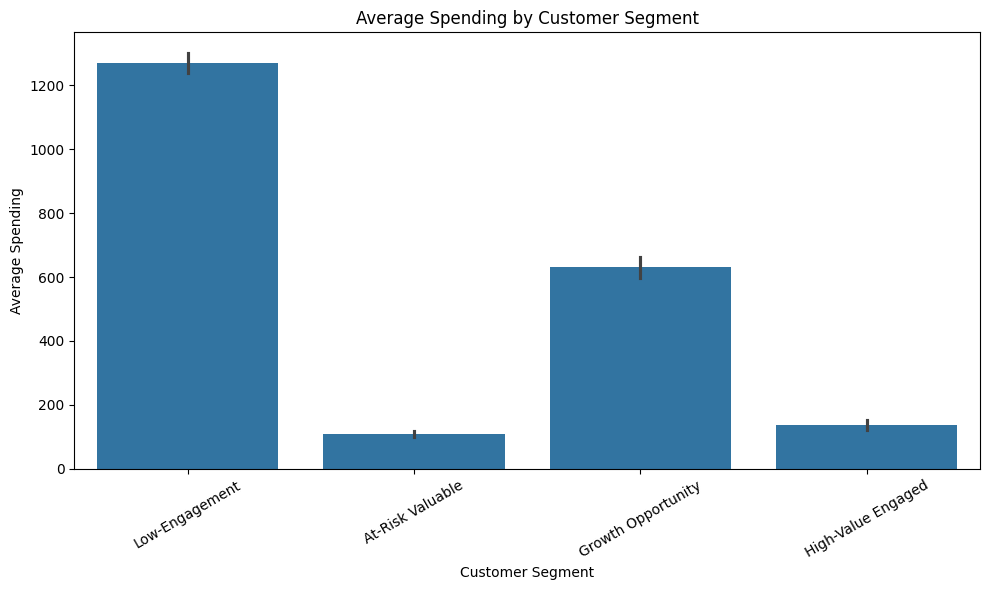

In [141]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x='Segment',
    y='Total_Spending',
    estimator='mean'
)

plt.title('Average Spending by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Average Spending')

plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    "Desktop/outputs/average_spending_by_segment.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

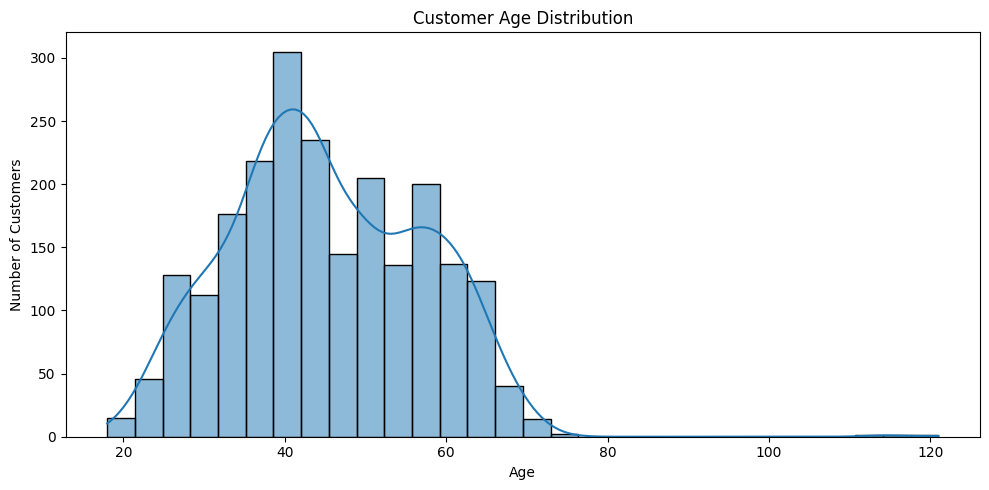

In [145]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['Age'],
    bins=30,
    kde=True
)

plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.savefig(
    "Desktop/outputs/customer_age_distribution.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

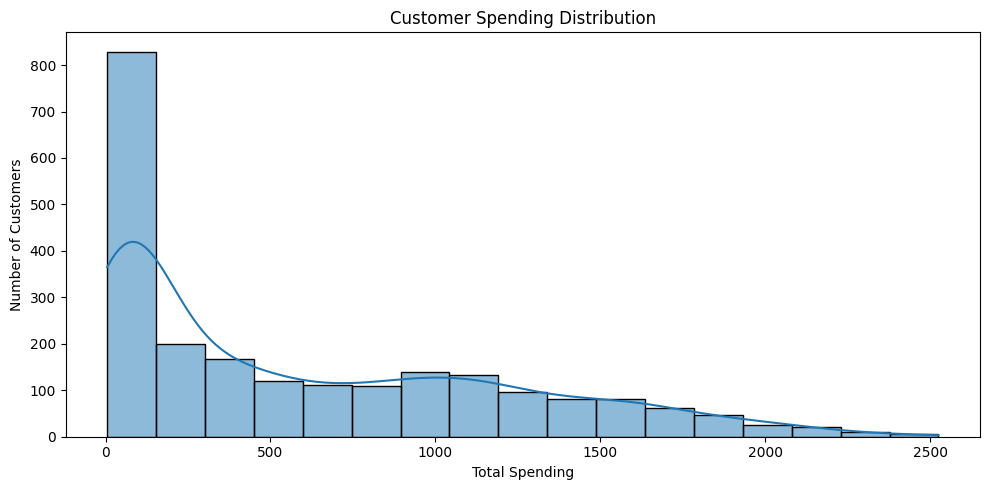

In [148]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['Total_Spending'],
    kde=True
)

plt.title('Customer Spending Distribution')
plt.xlabel('Total Spending')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.savefig(
    "Desktop/outputs/spending_distribution.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

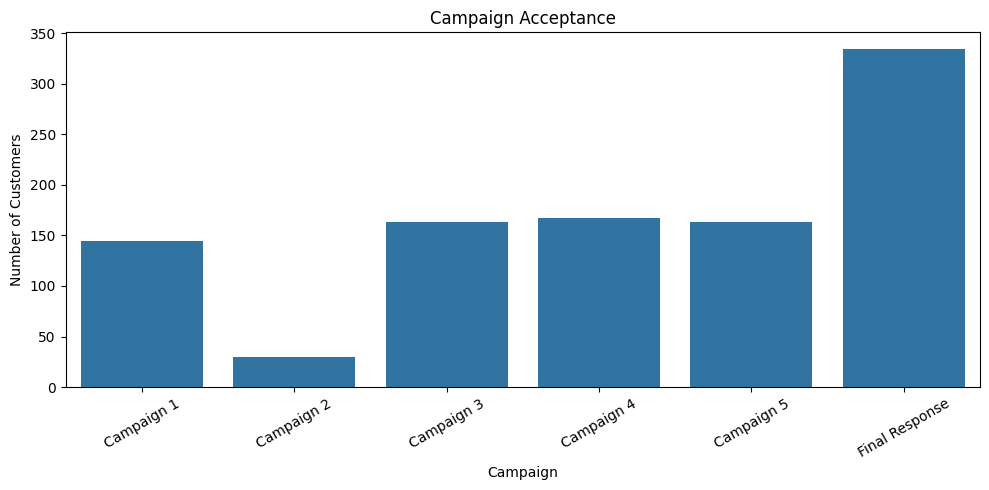

Campaign acceptance chart saved successfully!


In [200]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare campaign data
campaign_acceptance = {
    'Campaign 1': df['AcceptedCmp1'].sum(),
    'Campaign 2': df['AcceptedCmp2'].sum(),
    'Campaign 3': df['AcceptedCmp3'].sum(),
    'Campaign 4': df['AcceptedCmp4'].sum(),
    'Campaign 5': df['AcceptedCmp5'].sum(),
    'Final Response': df['Response'].sum()
}

campaign_df = pd.DataFrame(
    list(campaign_acceptance.items()),
    columns=['Campaign', 'Accepted_Customers']
)

# Create a NEW figure
fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=campaign_df,
    x='Campaign',
    y='Accepted_Customers',
    ax=ax
)

ax.set_title('Campaign Acceptance')
ax.set_xlabel('Campaign')
ax.set_ylabel('Number of Customers')
ax.tick_params(axis='x', rotation=30)

fig.tight_layout()

# IMPORTANT: Save BEFORE displaying
fig.savefig(
    "Desktop/outputs/campaign_acceptance.png",
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

# Close this figure after saving
plt.close(fig)

print("Campaign acceptance chart saved successfully!")

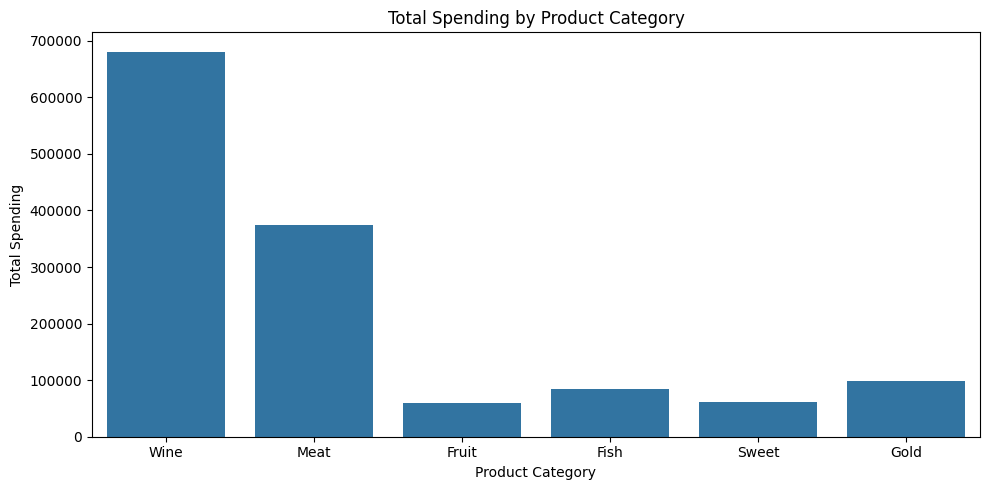

Product spending chart saved!


In [202]:
product_spending = {
    'Wine': df['MntWines'].sum(),
    'Meat': df['MntMeatProducts'].sum(),
    'Fruit': df['MntFruits'].sum(),
    'Fish': df['MntFishProducts'].sum(),
    'Sweet': df['MntSweetProducts'].sum(),
    'Gold': df['MntGoldProds'].sum()
}

product_spending_df = pd.DataFrame(
    list(product_spending.items()),
    columns=['Product_Category', 'Total_Spending']
)

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=product_spending_df,
    x='Product_Category',
    y='Total_Spending',
    ax=ax
)

ax.set_title('Total Spending by Product Category')
ax.set_xlabel('Product Category')
ax.set_ylabel('Total Spending')

fig.tight_layout()

fig.savefig(
    "Desktop/outputs/product_spending.png",
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()
plt.close(fig)

print("Product spending chart saved!")

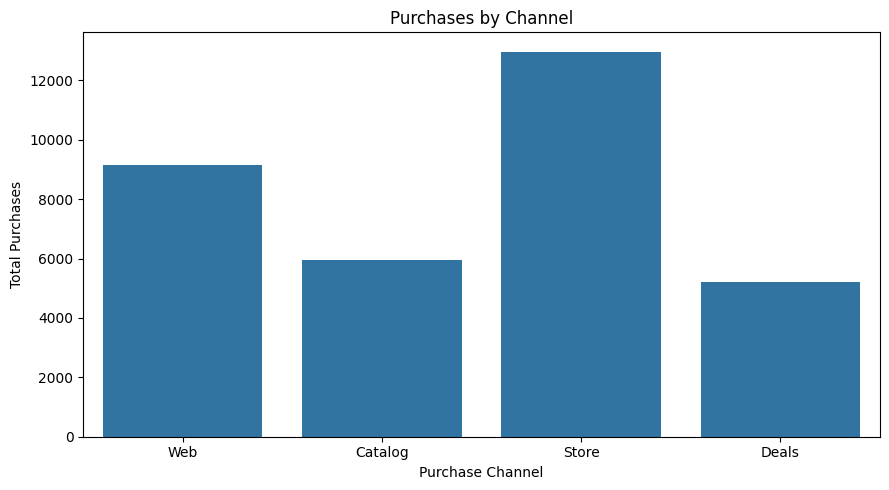

Purchase channel chart saved!


In [204]:
channel_purchases = {
    'Web': df['NumWebPurchases'].sum(),
    'Catalog': df['NumCatalogPurchases'].sum(),
    'Store': df['NumStorePurchases'].sum(),
    'Deals': df['NumDealsPurchases'].sum()
}

channel_df = pd.DataFrame(
    list(channel_purchases.items()),
    columns=['Channel', 'Total_Purchases']
)

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=channel_df,
    x='Channel',
    y='Total_Purchases',
    ax=ax
)

ax.set_title('Purchases by Channel')
ax.set_xlabel('Purchase Channel')
ax.set_ylabel('Total Purchases')

fig.tight_layout()

fig.savefig(
    "Desktop/outputs/purchase_channels.png",
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()
plt.close(fig)

print("Purchase channel chart saved!")

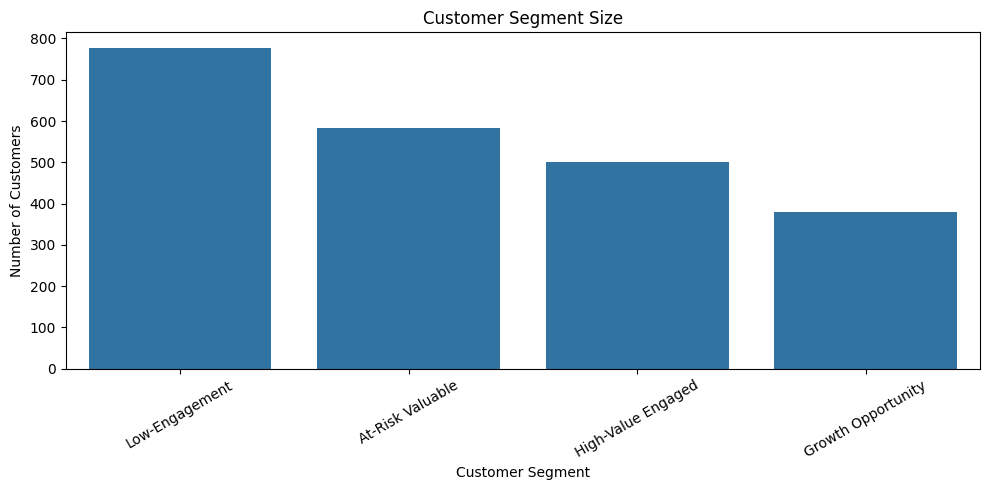

Segment size chart saved!


In [206]:
segment_counts = df['Segment'].value_counts()

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    x=segment_counts.index,
    y=segment_counts.values,
    ax=ax
)

ax.set_title('Customer Segment Size')
ax.set_xlabel('Customer Segment')
ax.set_ylabel('Number of Customers')
ax.tick_params(axis='x', rotation=30)

fig.tight_layout()

fig.savefig(
    "Desktop/outputs/segment_size.png",
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()
plt.close(fig)

print("Segment size chart saved!")

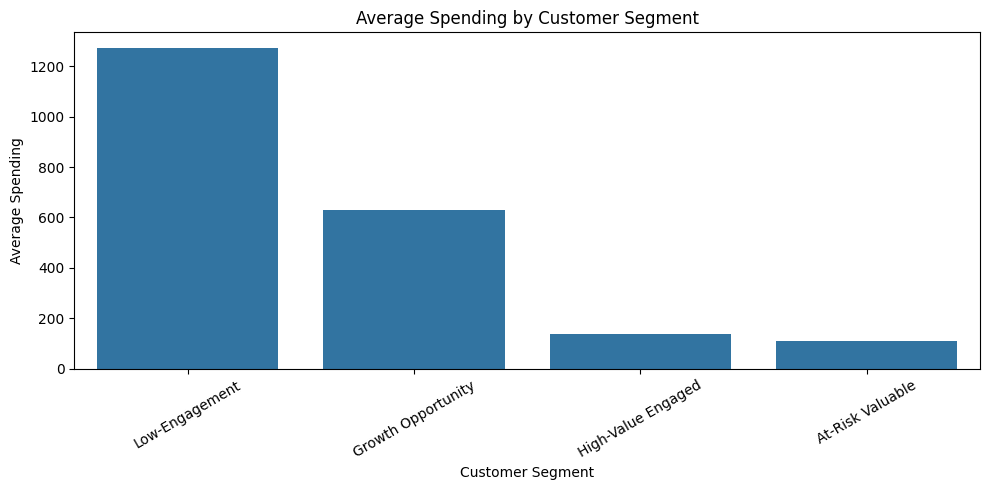

Spending by segment chart saved!


In [208]:
segment_spending = (
    df.groupby('Segment')['Total_Spending']
    .mean()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    x=segment_spending.index,
    y=segment_spending.values,
    ax=ax
)

ax.set_title('Average Spending by Customer Segment')
ax.set_xlabel('Customer Segment')
ax.set_ylabel('Average Spending')
ax.tick_params(axis='x', rotation=30)

fig.tight_layout()

fig.savefig(
    "Desktop/outputs/spending_by_segment.png",
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()
plt.close(fig)

print("Spending by segment chart saved!")

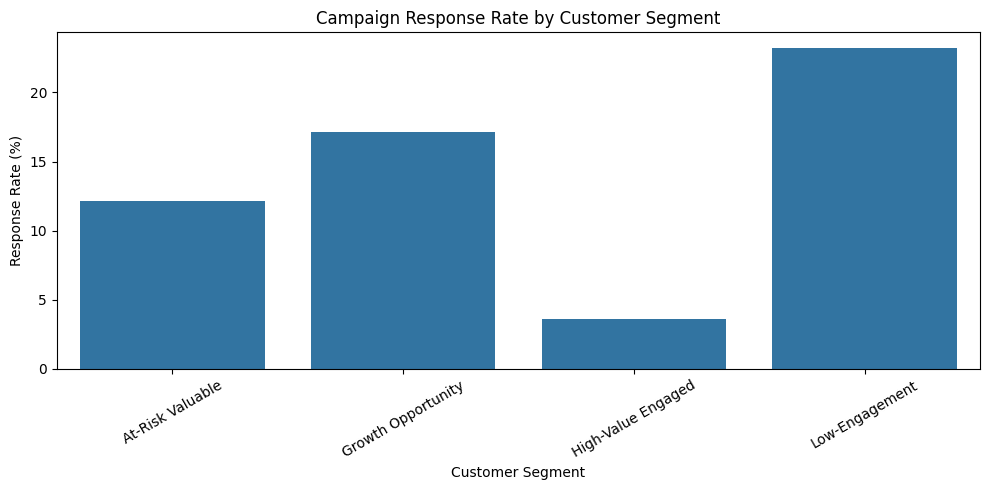

Response by segment chart saved!


In [210]:
response_segment = (
    df.groupby('Segment')['Response']
    .mean()
    .mul(100)
)

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    x=response_segment.index,
    y=response_segment.values,
    ax=ax
)

ax.set_title('Campaign Response Rate by Customer Segment')
ax.set_xlabel('Customer Segment')
ax.set_ylabel('Response Rate (%)')
ax.tick_params(axis='x', rotation=30)

fig.tight_layout()

fig.savefig(
    "Desktop/outputs/response_by_segment.png",
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()
plt.close(fig)

print("Response by segment chart saved!")

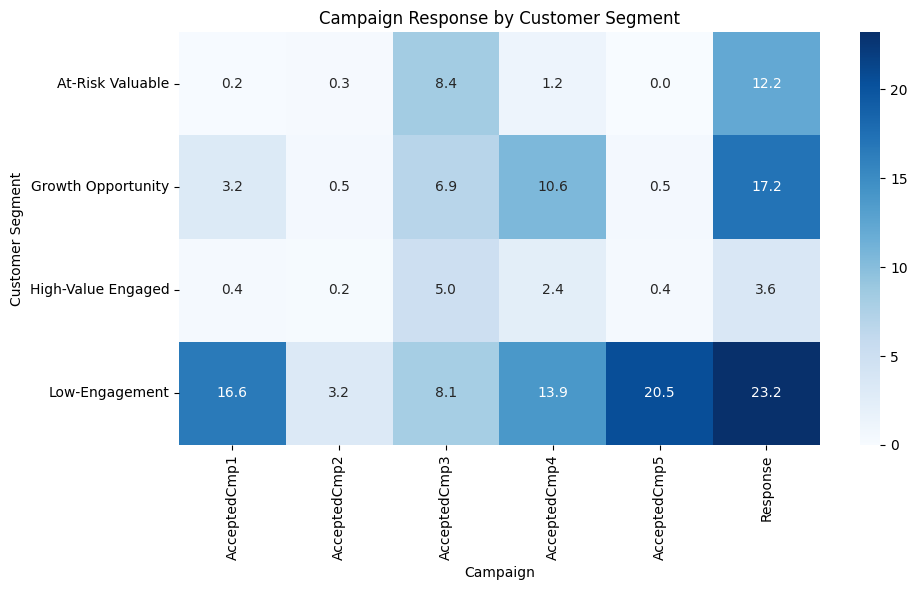

Campaign segment heatmap saved!


In [212]:
campaign_segment = df.groupby('Segment')[
    ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3',
     'AcceptedCmp4', 'AcceptedCmp5', 'Response']
].mean() * 100

fig, ax = plt.subplots(figsize=(10, 6))

sns.heatmap(
    campaign_segment,
    annot=True,
    fmt='.1f',
    cmap='Blues',
    ax=ax
)

ax.set_title('Campaign Response by Customer Segment')
ax.set_xlabel('Campaign')
ax.set_ylabel('Customer Segment')

fig.tight_layout()

fig.savefig(
    "Desktop/outputs/campaign_segment_heatmap.png",
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()
plt.close(fig)

print("Campaign segment heatmap saved!")

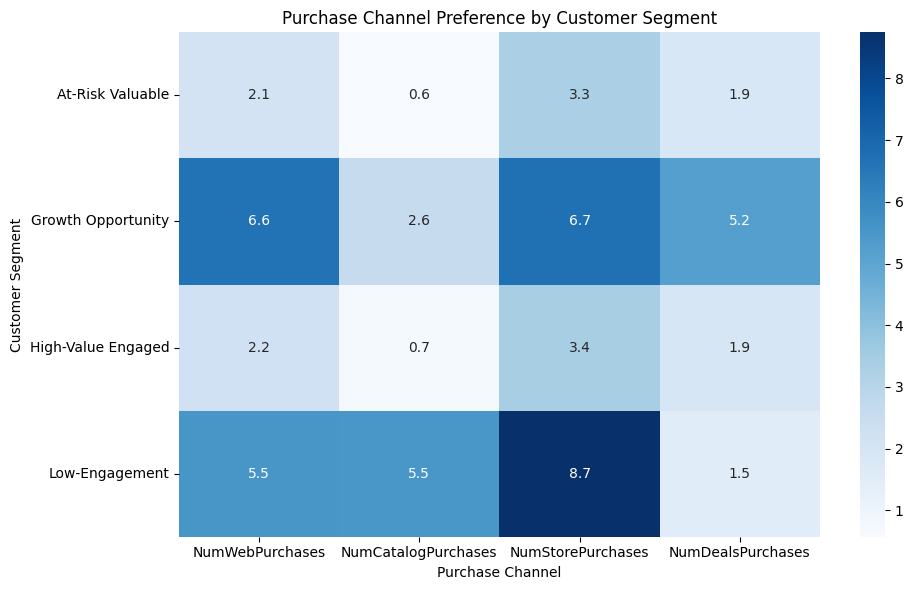

Channel segment heatmap saved!


In [214]:
channel_segment = df.groupby('Segment')[
    ['NumWebPurchases',
     'NumCatalogPurchases',
     'NumStorePurchases',
     'NumDealsPurchases']
].mean()

fig, ax = plt.subplots(figsize=(10, 6))

sns.heatmap(
    channel_segment,
    annot=True,
    fmt='.1f',
    cmap='Blues',
    ax=ax
)

ax.set_title('Purchase Channel Preference by Customer Segment')
ax.set_xlabel('Purchase Channel')
ax.set_ylabel('Customer Segment')

fig.tight_layout()

fig.savefig(
    "Desktop/outputs/channel_segment_heatmap.png",
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()
plt.close(fig)

print("Channel segment heatmap saved!")

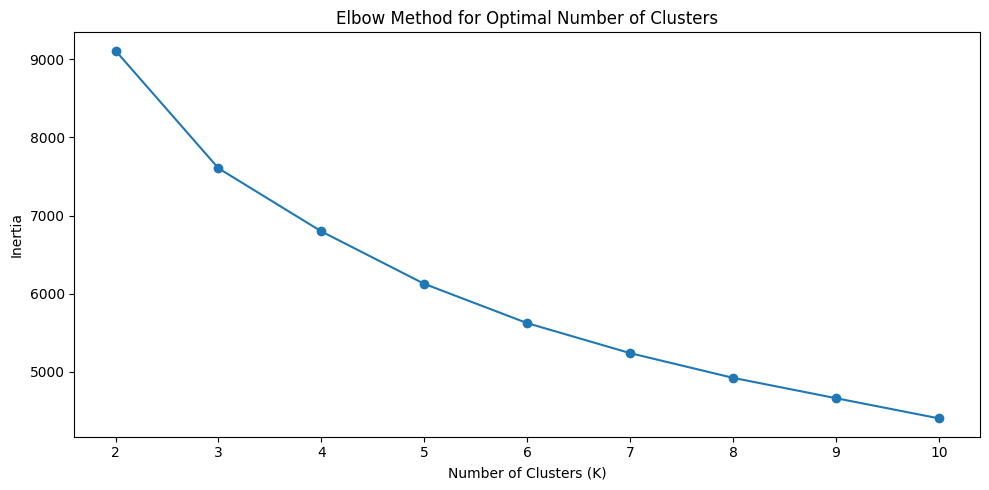

Elbow method chart saved!


In [216]:
inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    range(2, 11),
    inertia,
    marker='o'
)

ax.set_title('Elbow Method for Optimal Number of Clusters')
ax.set_xlabel('Number of Clusters (K)')
ax.set_ylabel('Inertia')

fig.tight_layout()

fig.savefig(
    "Desktop/outputs/elbow_method.png",
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()
plt.close(fig)

print("Elbow method chart saved!")

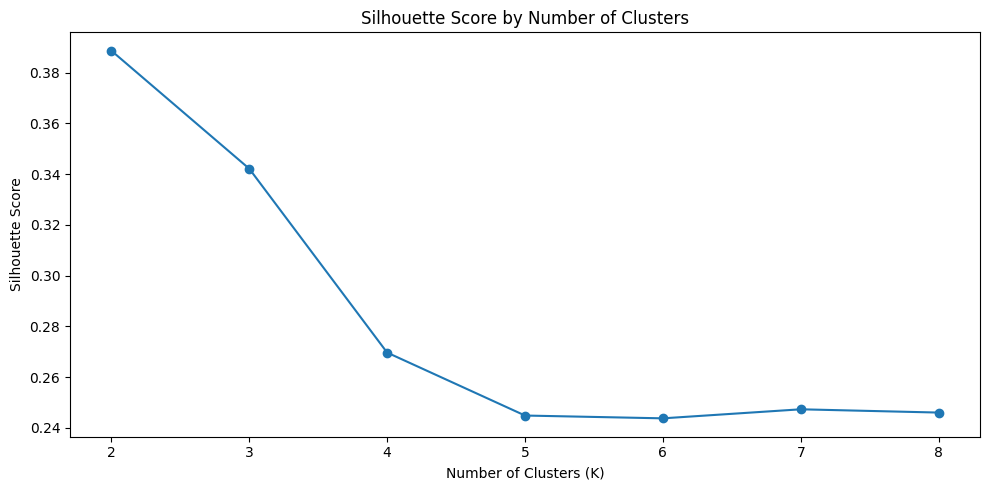

Silhouette score chart saved!


In [218]:
silhouette_scores = {}

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(X)
    
    score = silhouette_score(X, labels)
    silhouette_scores[k] = score

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    list(silhouette_scores.keys()),
    list(silhouette_scores.values()),
    marker='o'
)

ax.set_title('Silhouette Score by Number of Clusters')
ax.set_xlabel('Number of Clusters (K)')
ax.set_ylabel('Silhouette Score')

fig.tight_layout()

fig.savefig(
    "Desktop/outputs/silhouette_scores.png",
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()
plt.close(fig)

print("Silhouette score chart saved!")

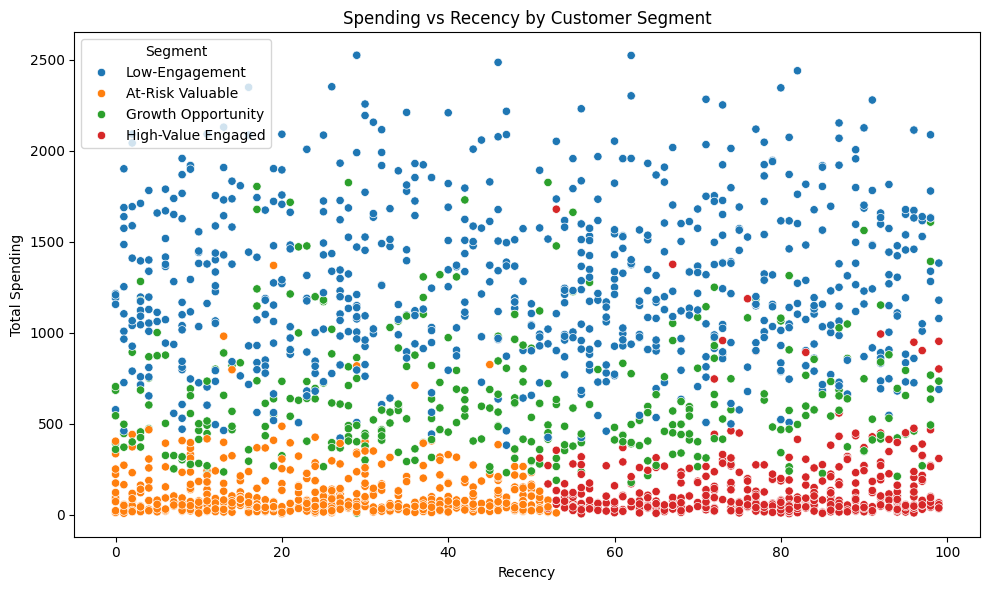

Spending vs recency chart saved!


In [220]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Recency',
    y='Total_Spending',
    hue='Segment',
    ax=ax
)

ax.set_title('Spending vs Recency by Customer Segment')
ax.set_xlabel('Recency')
ax.set_ylabel('Total Spending')

fig.tight_layout()

fig.savefig(
    "Desktop/outputs/spending_vs_recency.png",
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()
plt.close(fig)

print("Spending vs recency chart saved!")

In [160]:
plt.tight_layout()
plt.savefig(
    "Desktop/outputs/campaign_segment_heatmap.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

<Figure size 640x480 with 0 Axes>

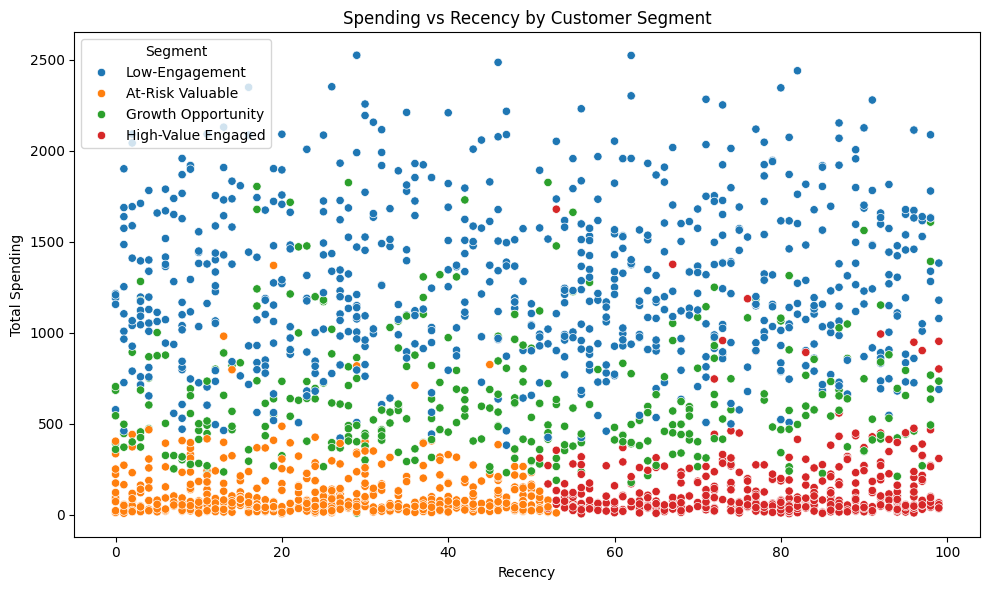

In [161]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Recency',
    y='Total_Spending',
    hue='Segment'
)

plt.title('Spending vs Recency by Customer Segment')
plt.xlabel('Recency')
plt.ylabel('Total Spending')
plt.legend(title='Segment')

plt.tight_layout()
plt.savefig(
    "Desktop/outputs/spending_vs_recency.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [164]:
plt.tight_layout()

plt.savefig(
    "Desktop/outputs/filename.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

<Figure size 640x480 with 0 Axes>

In [224]:
print("Final dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nSegments:")
print(df['Segment'].value_counts())

Final dataset shape: (2240, 38)

Missing values:
24

Duplicate rows:
0

Segments:
Segment
Low-Engagement        776
At-Risk Valuable      584
High-Value Engaged    501
Growth Opportunity    379
Name: count, dtype: int64


In [222]:
import os

output_files = [
    "customer_age_distribution.png",
    "spending_distribution.png",
    "product_spending.png",
    "purchase_channels.png",
    "campaign_acceptance.png",
    "elbow_method.png",
    "silhouette_scores.png",
    "segment_size.png",
    "spending_by_segment.png",
    "response_by_segment.png",
    "campaign_segment_heatmap.png",
    "channel_segment_heatmap.png",
    "spending_vs_recency.png"
]

for file in output_files:
    path = os.path.join("Desktop/outputs", file)
    
    if os.path.exists(path):
        print("✓", file)
    else:
        print("✗ MISSING:", file)

✓ customer_age_distribution.png
✓ spending_distribution.png
✓ product_spending.png
✓ purchase_channels.png
✓ campaign_acceptance.png
✓ elbow_method.png
✓ silhouette_scores.png
✓ segment_size.png
✓ spending_by_segment.png
✓ response_by_segment.png
✓ campaign_segment_heatmap.png
✓ channel_segment_heatmap.png
✓ spending_vs_recency.png
